In [2]:
!pip install scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 4.8 MB/s eta 0:00:00


최종 후보조건 추천값: [[0.5, 3.639063831912961, 20.0]]

최종 후보조건 분석
실제 수행조건: Esculetin=0.50 mM, OD600=3.6, 시간=20.0 h
실제 반복 평균: 93.89 mAU·min
실제 반복 SD: 2.90 mAU·min
실제 반복 CV: 3.09%
실제 수행조건의 GP 예측 평균: 109.12 mAU·min
실제 수행조건의 GP 예측 SD: 12.64 mAU·min
실제 수행조건의 근사 95% 예측구간: 84.35–133.90

기준조건 평균: 41.41 mAU·min
기준조건 SD: 1.02 mAU·min
기준조건 CV: 2.47%
기준조건 대비 상대 증가율: 126.75%

BO 추천조건의 GP 예측
예측 평균: 109.10 mAU·min
예측 SD: 12.94 mAU·min
근사 95% 예측구간: 83.74–134.47


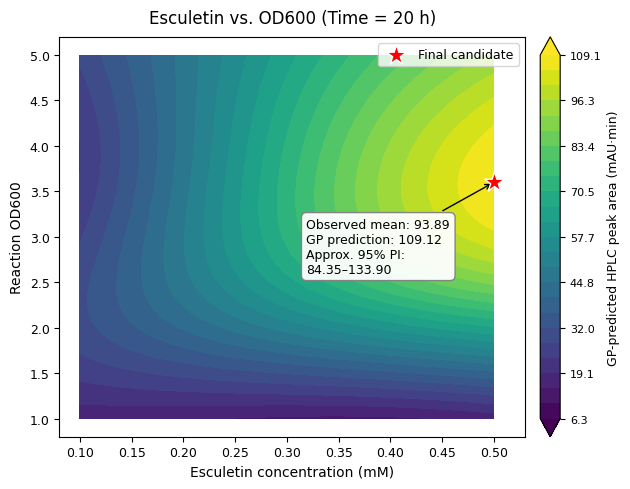

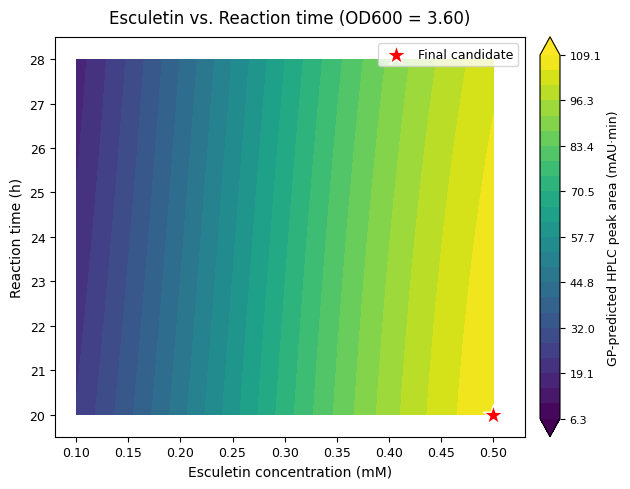

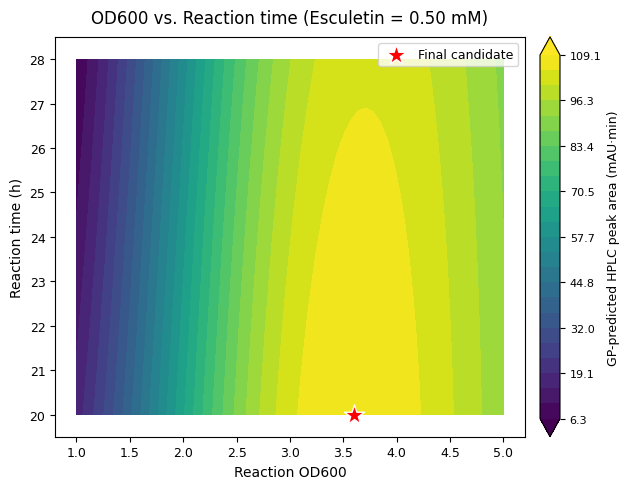

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from skopt import Optimizer
from skopt.space import Real


# 초기 실험 6개와 HPLC 피크 면적
initial_X = [
    [0.27, 4.3, 26.5],
    [0.45, 2.8, 24.0],
    [0.33, 3.0, 25.8],
    [0.16, 2.0, 20.3],
    [0.12, 3.9, 22.9],
    [0.40, 1.2, 27.6]
]

initial_peak_area = np.array([
    59.73035,
    89.929575,
    71.5388,
    36.291,
    25.32945,
    10.59065
])

# 1차 BO 후보조건 및 기준조건의 실제 관측값
X_round2 = [
    [0.10, 2.7, 27.6],
    [0.43, 5.0, 26.7],
    [0.20, 3.0, 24.0]
]

peak_area_round2 = np.array([
    18.892,
    83.1772,
    44.0013
])

# 실제 최종 검증 실험조건과 반복 측정값
final_X = np.array([
    [0.50, 3.60, 20.0]
])

final_replicates = np.array([
    95.2801,
    90.5529,
    95.8291
])

baseline_replicates = np.array([
    42.1695,
    41.8060,
    40.2423
])

actual_mean = np.mean(final_replicates)
actual_sd = np.std(final_replicates, ddof=1)
actual_cv = actual_sd / actual_mean * 100

baseline_mean = np.mean(baseline_replicates)
baseline_sd = np.std(baseline_replicates, ddof=1)
baseline_cv = baseline_sd / baseline_mean * 100

improvement_pct = (
    (actual_mean - baseline_mean) / baseline_mean * 100
)

# Bayesian optimization 설정
space = [
    Real(0.1, 0.5, name="Esculetin_mM"),
    Real(1.0, 5.0, name="Reaction_OD600"),
    Real(20.0, 28.0, name="Reaction_Time_h")
]

optimizer = Optimizer(
    dimensions=space,
    base_estimator="GP",
    acq_func="EI",
    n_initial_points=6,
    random_state=42
)

# 초기 6개 데이터로 GP 학습
optimizer.tell(
    initial_X,
    (-initial_peak_area).tolist()
)

# 기존 BO의 후보 추천 호출 순서를 재현
next_candidates = optimizer.ask(n_points=2)

# 1차 BO 결과 및 기준조건을 누적 반영
optimizer.tell(
    X_round2,
    (-peak_area_round2).tolist()
)

# 최종 후보조건 추천 시점의 모델 상태 재현
next_candidates_r3 = optimizer.ask(n_points=1)

print("최종 후보조건 추천값:", next_candidates_r3)

# 최종 검증 결과를 반영하기 전의 GP 모델 사용
gp_model = optimizer.models[-1]


def predict_peak_area(X):
    """입력조건에서 GP 예측 평균과 예측 표준편차를 반환한다."""
    X_transformed = optimizer.space.transform(
        np.asarray(X, dtype=float).tolist()
    )

    pred_negative, pred_sd = gp_model.predict(
        X_transformed,
        return_std=True
    )

    pred_area = -np.asarray(pred_negative, dtype=float)

    return pred_area, np.asarray(pred_sd, dtype=float)


# BO 추천조건과 실제 수행조건에서의 예측값 계산
recommended_X = np.asarray(
    next_candidates_r3,
    dtype=float
)

recommended_pred, recommended_sd = predict_peak_area(
    recommended_X
)

actual_pred, actual_pred_sd = predict_peak_area(
    final_X
)

print("\n최종 후보조건 분석")
print(f"실제 수행조건: Esculetin={final_X[0, 0]:.2f} mM, "
      f"OD600={final_X[0, 1]:.1f}, "
      f"시간={final_X[0, 2]:.1f} h")

print(f"실제 반복 평균: {actual_mean:.2f} mAU·min")
print(f"실제 반복 SD: {actual_sd:.2f} mAU·min")
print(f"실제 반복 CV: {actual_cv:.2f}%")
print(f"실제 수행조건의 GP 예측 평균: {actual_pred[0]:.2f} mAU·min")
print(f"실제 수행조건의 GP 예측 SD: {actual_pred_sd[0]:.2f} mAU·min")
print(
    "실제 수행조건의 근사 95% 예측구간: "
    f"{actual_pred[0] - 1.96 * actual_pred_sd[0]:.2f}–"
    f"{actual_pred[0] + 1.96 * actual_pred_sd[0]:.2f}"
)

print(f"\n기준조건 평균: {baseline_mean:.2f} mAU·min")
print(f"기준조건 SD: {baseline_sd:.2f} mAU·min")
print(f"기준조건 CV: {baseline_cv:.2f}%")
print(f"기준조건 대비 상대 증가율: {improvement_pct:.2f}%")

print("\nBO 추천조건의 GP 예측")
print(f"예측 평균: {recommended_pred[0]:.2f} mAU·min")
print(f"예측 SD: {recommended_sd[0]:.2f} mAU·min")
print(
    "근사 95% 예측구간: "
    f"{recommended_pred[0] - 1.96 * recommended_sd[0]:.2f}–"
    f"{recommended_pred[0] + 1.96 * recommended_sd[0]:.2f}"
)


# 반응면은 최종 후보조건의 각 변수를 기준으로 고정한다.
fixed_time = 20.0
fixed_od = 3.60
fixed_esculetin = 0.50

n_grid = 60

esc_grid = np.linspace(0.1, 0.5, n_grid)
od_grid = np.linspace(1.0, 5.0, n_grid)
time_grid = np.linspace(20.0, 28.0, n_grid)


def make_surface(X):
    """격자 입력값에 대한 GP 예측 피크 면적을 계산한다."""
    pred, _ = predict_peak_area(X)
    return pred


# 반응면 1: Esculetin 농도 × OD600, 반응시간 20 h 고정
E1, O1 = np.meshgrid(esc_grid, od_grid)

X1 = np.column_stack([
    E1.ravel(),
    O1.ravel(),
    np.full(E1.size, fixed_time)
])

Z1 = make_surface(X1).reshape(E1.shape)


# 반응면 2: Esculetin 농도 × 반응시간, OD600 3.60 고정
E2, T2 = np.meshgrid(esc_grid, time_grid)

X2 = np.column_stack([
    E2.ravel(),
    np.full(E2.size, fixed_od),
    T2.ravel()
])

Z2 = make_surface(X2).reshape(E2.shape)


# 반응면 3: OD600 × 반응시간, Esculetin 0.50 mM 고정
O3, T3 = np.meshgrid(od_grid, time_grid)

X3 = np.column_stack([
    np.full(O3.size, fixed_esculetin),
    O3.ravel(),
    T3.ravel()
])

Z3 = make_surface(X3).reshape(O3.shape)


# 세 반응면에서 동일한 색상 범위를 사용한다.
all_predictions = np.concatenate([
    Z1.ravel(),
    Z2.ravel(),
    Z3.ravel()
])

vmin = all_predictions.min()
vmax = all_predictions.max()
levels = np.linspace(vmin, vmax, 25)



plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9
})


# 최종 후보조건 실제 측정값과 GP 예측값
prediction_lower = float(
    actual_pred[0] - 1.96 * actual_pred_sd[0]
)
prediction_upper = float(
    actual_pred[0] + 1.96 * actual_pred_sd[0]
)

annotation = (
    f"Observed mean: {actual_mean:.2f}\n"
    f"GP prediction: {actual_pred[0]:.2f}\n"
    f"Approx. 95% PI:\n"
    f"{prediction_lower:.2f}–{prediction_upper:.2f}"
)


def plot_response_surface(
    X,
    Y,
    Z,
    title,
    xlabel,
    ylabel,
    candidate_x,
    candidate_y,
    filename,
    show_prediction=False
):
    fig, ax = plt.subplots(figsize=(6.4, 5.0))

    contour = ax.contourf(
        X,
        Y,
        Z,
        levels=levels,
        cmap="viridis",
        extend="both"
    )

    # 최종 후보조건
    ax.scatter(
        candidate_x,
        candidate_y,
        marker="*",
        s=230,
        c="red",
        edgecolors="white",
        linewidths=1,
        label="Final candidate",
        zorder=5,
        clip_on=False
    )

    # 첫 번째 그림에 실제 관측값과 GP 예측값 표시
    if show_prediction:
        ax.annotate(
            annotation,
            xy=(candidate_x, candidate_y),
            xytext=(-135, -65),
            textcoords="offset points",
            arrowprops={"arrowstyle": "->"},
            fontsize=9,
            bbox={
                "boxstyle": "round,pad=0.4",
                "fc": "white",
                "ec": "gray",
                "alpha": 0.95
            }
        )

    ax.set_title(title, pad=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(loc="best", frameon=True)

    # 후보조건이 탐색 범위 경계에 위치하므로 표시 공간 확보
    if "Esculetin vs. OD600" in title:
        ax.set_xlim(0.08, 0.53)
        ax.set_ylim(0.8, 5.2)
    elif "Esculetin vs. Reaction time" in title:
        ax.set_xlim(0.08, 0.53)
        ax.set_ylim(19.5, 28.5)
    else:
        ax.set_xlim(0.8, 5.2)
        ax.set_ylim(19.5, 28.5)

    cbar = fig.colorbar(
        contour,
        ax=ax,
        pad=0.03,
        fraction=0.05
    )
    cbar.set_label(
        "GP-predicted HPLC peak area (mAU·min)",
        fontsize=9
    )
    cbar.ax.tick_params(labelsize=8)

    fig.tight_layout()

    # 고해상도 PNG와 벡터 PDF 저장
    plt.savefig(
        filename + ".png",
        dpi=600,
        bbox_inches="tight"
    )
    plt.savefig(
        filename + ".pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# 그림 A: Esculetin 농도 × OD600, 반응시간 20 h
plot_response_surface(
    E1, O1, Z1,
    title="Esculetin vs. OD600 (Time = 20 h)",
    xlabel="Esculetin concentration (mM)",
    ylabel="Reaction OD600",
    candidate_x=0.50,
    candidate_y=3.60,
    filename="GP_surface_A_Esculetin_OD600",
    show_prediction=True
)

# 그림 B: Esculetin 농도 × 반응시간, OD600 3.60
plot_response_surface(
    E2, T2, Z2,
    title="Esculetin vs. Reaction time (OD600 = 3.60)",
    xlabel="Esculetin concentration (mM)",
    ylabel="Reaction time (h)",
    candidate_x=0.50,
    candidate_y=20.0,
    filename="GP_surface_B_Esculetin_Time"
)

# 그림 C: OD600 × 반응시간, Esculetin 0.50 mM
plot_response_surface(
    O3, T3, Z3,
    title="OD600 vs. Reaction time (Esculetin = 0.50 mM)",
    xlabel="Reaction OD600",
    ylabel="Reaction time (h)",
    candidate_x=3.60,
    candidate_y=20.0,
    filename="GP_surface_C_OD600_Time"
)
